In [1]:
"""
Hyperspectral Data Analysis for Enzyme Prediction using GA-PLS
================================================================
Complete pipeline for feature selection and modeling of maize enzyme concentrations
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter
from scipy import signal
from sklearn.preprocessing import StandardScaler
from sklearn.cross_decomposition import PLSRegression
from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.decomposition import PCA
import warnings
warnings.filterwarnings('ignore')

In [2]:
# ==============================================================================
# 1. DATA LOADING AND EXPLORATION
# ==============================================================================

def load_data(spectral_path, enzyme_path):
    """
    Load hyperspectral and enzyme concentration data
    
    Parameters:
    -----------
    spectral_path : str
        Path to CSV file with spectral data (samples x wavelengths)
    enzymes_path : str
        Path to CSV file with enzyme concentrations (samples x enzymes)
    """
    print("Loading data...")
    X = pd.read_csv(spectral_path)
    y = pd.read_csv(enzyme_path)
    # X = pd.read_csv('data/waves.csv')
    # y = pd.read_csv('data/enzymes.csv')
    
    print(f"Spectral data shape: {X.shape}")
    print(f"Enzyme data shape: {y.shape}")
    
    # Check for missing values
    print(f"\nMissing values in spectral data: {X.isnull().sum().sum()}")
    print(f"Missing values in enzyme data: {y.isnull().sum().sum()}")
    
    return X, y

def explore_data(X, y, wavelengths=None):
    """
    Visualize and explore the dataset
    """
    print("\n" + "="*70)
    print("DATA EXPLORATION")
    print("="*70)
    
    # Spectral data statistics
    print("\nSpectral Data Statistics:")
    print(f"Mean spectrum range: [{X.mean().min():.4f}, {X.mean().max():.4f}]")
    print(f"Std spectrum range: [{X.std().min():.4f}, {X.std().max():.4f}]")
    
    # Enzyme statistics
    print("\nEnzyme Concentration Statistics:")
    print(y.describe())
    
    # Plot mean spectrum with variability
    fig, axes = plt.subplots(2, 1, figsize=(14, 8))
    
    mean_spectrum = X.mean(axis=0)
    std_spectrum = X.std(axis=0)
    x_axis = wavelengths
    
    axes[0].plot(x_axis, mean_spectrum, 'b-', linewidth=1.5, label='Mean')
    axes[0].fill_between(x_axis, mean_spectrum - std_spectrum, 
                          mean_spectrum + std_spectrum, alpha=0.3, label='±1 Std')
    axes[0].set_xlabel('Wavelength (nm)' if wavelengths is not None else 'Feature Index')
    axes[0].set_ylabel('Reflectance/Absorbance')
    axes[0].set_title('Mean Spectrum with Variability')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)
    
    # Plot enzyme distributions
    y.hist(bins=30, ax=axes[1], alpha=0.7, edgecolor='black')
    axes[1].set_title('Enzyme Concentration Distributions')
    axes[1].set_xlabel('Concentration')
    axes[1].set_ylabel('Frequency')
    
    plt.tight_layout()
    plt.show()
    plt.savefig('01_data_exploration.png', dpi=300, bbox_inches='tight')
    print("\nSaved: 01_data_exploration.png")
    plt.close()

In [3]:
# ==============================================================================
# 2. PREPROCESSING FUNCTIONS
# ==============================================================================

from sklearn.ensemble import IsolationForest

def remove_outliers(X, y):
    iso = IsolationForest(contamination=0.04, random_state=42)
    outliers = iso.fit_predict(X) == -1
    
    # Count and print the outliers
    num_outliers = outliers.sum()
    print(f"Number of outliers detected: {num_outliers}")

    if num_outliers > 0:
        print("Outlier values (X):")
        print(X[outliers])
        print("Corresponding target values (y):")
        print(y[outliers])
        
    X_clean, y_clean = X[~outliers], y[~outliers]
    
    return X_clean, y_clean, outliers


def snv(X):
    """
    Standard Normal Variate (SNV) transformation
    Removes multiplicative scatter effects
    """
    X_centered = X - X.mean(axis=1, keepdims=True)
    X_snv = X_centered / X.std(axis=1, keepdims=True)
    return X_snv

def msc(X):
    """
    Multiplicative Scatter Correction (MSC)
    """
    mean_spectrum = X.mean(axis=0)
    X_msc = np.zeros_like(X)
    
    for i in range(X.shape[0]):
        fit = np.polyfit(mean_spectrum, X[i, :], 1)
        X_msc[i, :] = (X[i, :] - fit[1]) / fit[0]
    
    return X_msc

def savitzky_golay_smooth(X, window_length=11, polyorder=2):
    """
    Savitzky-Golay smoothing filter
    """
    X_smooth = np.zeros_like(X)
    for i in range(X.shape[0]):
        X_smooth[i, :] = savgol_filter(X[i, :], window_length, polyorder)
    return X_smooth

# def savitzky_golay_derivative(X, deriv=1, window_length=11, polyorder=2):
#     """
#     Savitzky-Golay derivative (1st or 2nd order)
#     """
#     X_deriv = np.zeros_like(X)
#     for i in range(X.shape[0]):
#         X_deriv[i, :] = savgol_filter(X[i, :], window_length, polyorder, deriv=deriv)
#     return X_deriv

def preprocess_pipeline(X, baseline='msc', smooth=True, derivative=None, 
                        window_length=11, polyorder=2):
    """
    Complete preprocessing pipeline
    
    Parameters:
    -----------
    X : array-like
        Spectral data
    baseline : str
        'snv', 'msc', or None
    smooth : bool
        Apply Savitzky-Golay smoothing
    derivative : int or None
        Apply 1st or 2nd derivative, or None
    window_length : int
        Window for Savitzky-Golay filter (must be odd)
    polyorder : int
        Polynomial order for Savitzky-Golay filter
    """
    print("\n" + "="*70)
    print("PREPROCESSING")
    print("="*70)
    
    X_processed = X.copy()
    
    # Smoothing
    if smooth:
        print(f"Applying Savitzky-Golay smoothing (window={window_length}, poly={polyorder})...")
        X_processed = savitzky_golay_smooth(X_processed, window_length, polyorder)

    # Baseline correction
    if baseline == 'snv':
        print("Applying SNV (Standard Normal Variate)...")
        X_processed = snv(X_processed)
    elif baseline == 'msc':
        print("Applying MSC (Multiplicative Scatter Correction)...")
        X_processed = msc(X_processed)
    
    
    # Derivative
    # if derivative in [1, 2]:
    #     print(f"Applying {derivative}{'st' if derivative==1 else 'nd'} derivative transformation...")
    #     # X_processed = savitzky_golay_derivative(X_processed, derivative, window_length, polyorder)
    
    print("Preprocessing complete!")
    return X_processed

def visualize_preprocessing(X_raw, X_processed, sample_idx=1, wavelengths=None):
    """
    Visualize preprocessing effects
    """
    fig, axes = plt.subplots(2, 1, figsize=(14, 8))
    
    x_axis = wavelengths if wavelengths is not None else np.arange(X_raw.shape[1])
    
    axes[0].plot(x_axis, X_raw[sample_idx], 'b-', linewidth=1.5, label='Raw')
    axes[0].set_xlabel('Wavelength (nm)' if wavelengths is not None else 'Feature Index')
    axes[0].set_ylabel('Intensity')
    axes[0].set_title('Raw Spectrum (Sample 1)')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)
    
    axes[1].plot(x_axis, X_processed[sample_idx], 'r-', linewidth=1.5, label='Preprocessed')
    axes[1].set_xlabel('Wavelength (nm)' if wavelengths is not None else 'Feature Index')
    axes[1].set_ylabel('Intensity')
    axes[1].set_title('Preprocessed Spectrum (Sample 1)')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    plt.savefig('02_preprocessing_comparison.png', dpi=300, bbox_inches='tight')
    print("\nSaved: 02_preprocessing_comparison.png")
    plt.close()



HYPERSPECTRAL GA-PLS PIPELINE
Loading data...
Spectral data shape: (262, 1867)
Enzyme data shape: (262, 5)

Missing values in spectral data: 0
Missing values in enzyme data: 0

DATA EXPLORATION

Spectral Data Statistics:
Mean spectrum range: [0.1358, 1.4416]
Std spectrum range: [0.0608, 0.1891]

Enzyme Concentration Statistics:
                  1             2            3             4           5
count    262.000000    262.000000   262.000000    262.000000  262.000000
mean    2262.995210   2187.796978   632.750286   1992.357929    0.689928
std     1878.432128   2983.730816  1329.626812   2513.595281    1.797702
min       60.457715      0.000000     0.000000      0.000000    0.000000
25%     1001.897558    565.672935    25.039861      3.438299    0.000000
50%     1854.196934   1012.698828    80.457697   1315.529036    0.000000
75%     3025.382083   2379.473821   551.548826   2795.063640    0.378290
max    14928.435290  19932.201530  6367.691872  16345.518440   17.689908


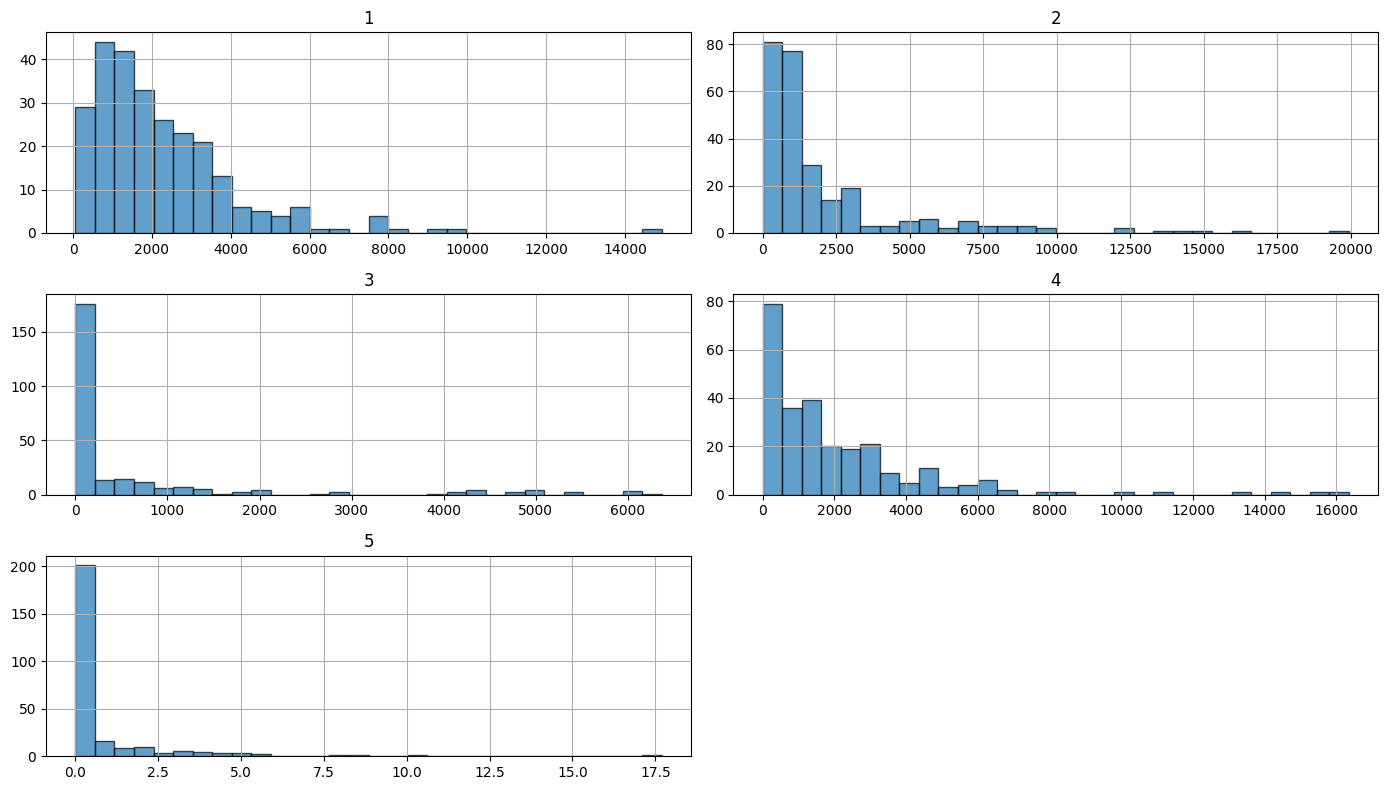


Saved: 01_data_exploration.png
Number of outliers detected: 11
Outlier values (X):
[[ 0.9141037   1.008995    1.029056   ... -0.06502139 -0.06477568
  -0.06468958]
 [ 1.299842    1.283169    1.386707   ...  0.3203063   0.3202472
   0.320182  ]
 [ 1.414659    1.326538    1.345896   ...  0.3547938   0.3537387
   0.3531892 ]
 ...
 [ 0.8891448   1.05208     1.190228   ...  0.2203151   0.2201398
   0.2205692 ]
 [ 1.271182    1.502196    1.596985   ...  0.2446101   0.2435008
   0.2437963 ]
 [ 0.          1.690472    1.433416   ...  0.05931595  0.05883365
   0.05852154]]
Corresponding target values (y):
[[5.56090537e+02 1.20139145e+03 5.40883589e+03 0.00000000e+00
  0.00000000e+00]
 [3.52504096e+03 8.88801402e+02 7.27559809e+01 2.06642189e+03
  1.15804994e+00]
 [1.25034928e+03 1.82016171e+03 1.18412982e+01 1.53441802e+03
  0.00000000e+00]
 [1.95782045e+03 2.21188023e+03 3.63600828e+01 2.12730281e+03
  0.00000000e+00]
 [3.49745464e+03 3.00177096e+03 6.41256041e+01 3.07854219e+03
  0.00000000e

In [4]:
# ==============================================================================
# USAGE EXAMPLE
# ==============================================================================

# Define file paths
spectral_path = 'data/waves.csv'
enzyme_path = 'data/enzymes.csv'

# Optional: Define wavelengths and enzyme names
wavelengths = np.arange(1, 1868, 1)  # Use feature indices if wavelengths unknown

enzyme_names = ['Enzyme_1', 'Enzyme_2', 'Enzyme_3', 'Enzyme_4', 'Enzyme_5']

print("\n" + "="*70)
print("HYPERSPECTRAL GA-PLS PIPELINE")
print("="*70)

# 1. Load data
X, y = load_data(spectral_path, enzyme_path)

# 2. Data exploration
explore_data(X, y, wavelengths)

X = X.values if isinstance(X, pd.DataFrame) else X
y = y.values if isinstance(y, pd.DataFrame) else y

# 3. Remove outliers
X, y, outliers = remove_outliers(X, y)

In [5]:
print(X.shape, y.shape)

(251, 1867) (251, 5)



PREPROCESSING
Applying Savitzky-Golay smoothing (window=11, poly=2)...
Applying SNV (Standard Normal Variate)...
Preprocessing complete!


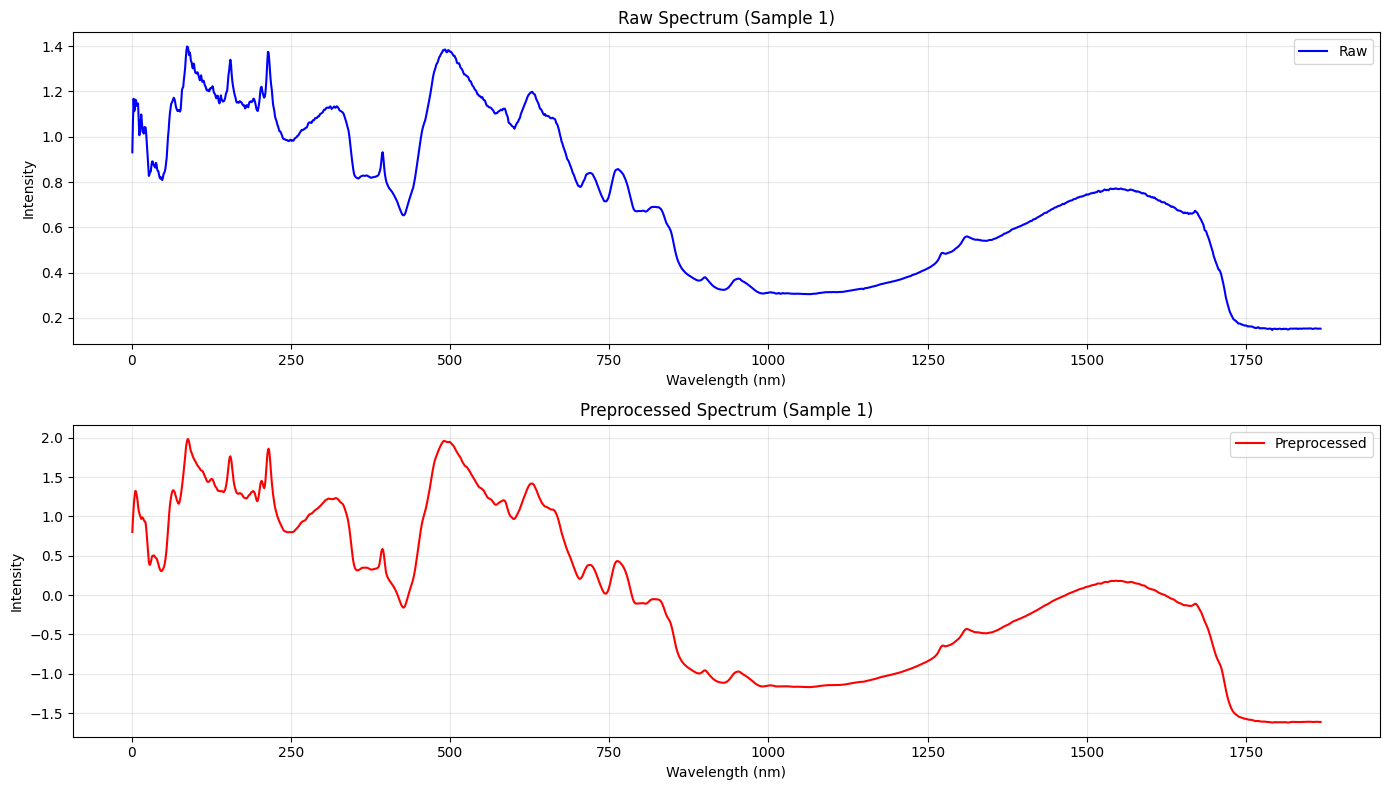


Saved: 02_preprocessing_comparison.png

Analysis complete! Check the generated files:
- 02_preprocessing_comparison.png


In [6]:
# 4. Preprocessing
X_raw = X.copy()
X_processed = preprocess_pipeline(X, baseline='snv', smooth=True, 
                                    derivative=1, window_length=11,
                                    polyorder=2)
visualize_preprocessing(X_raw, X_processed, sample_idx=0, wavelengths=wavelengths)

print("\nAnalysis complete! Check the generated files:")
print("- 02_preprocessing_comparison.png")


PREPROCESSING
Applying Savitzky-Golay smoothing (window=11, poly=2)...
Applying MSC (Multiplicative Scatter Correction)...
Preprocessing complete!


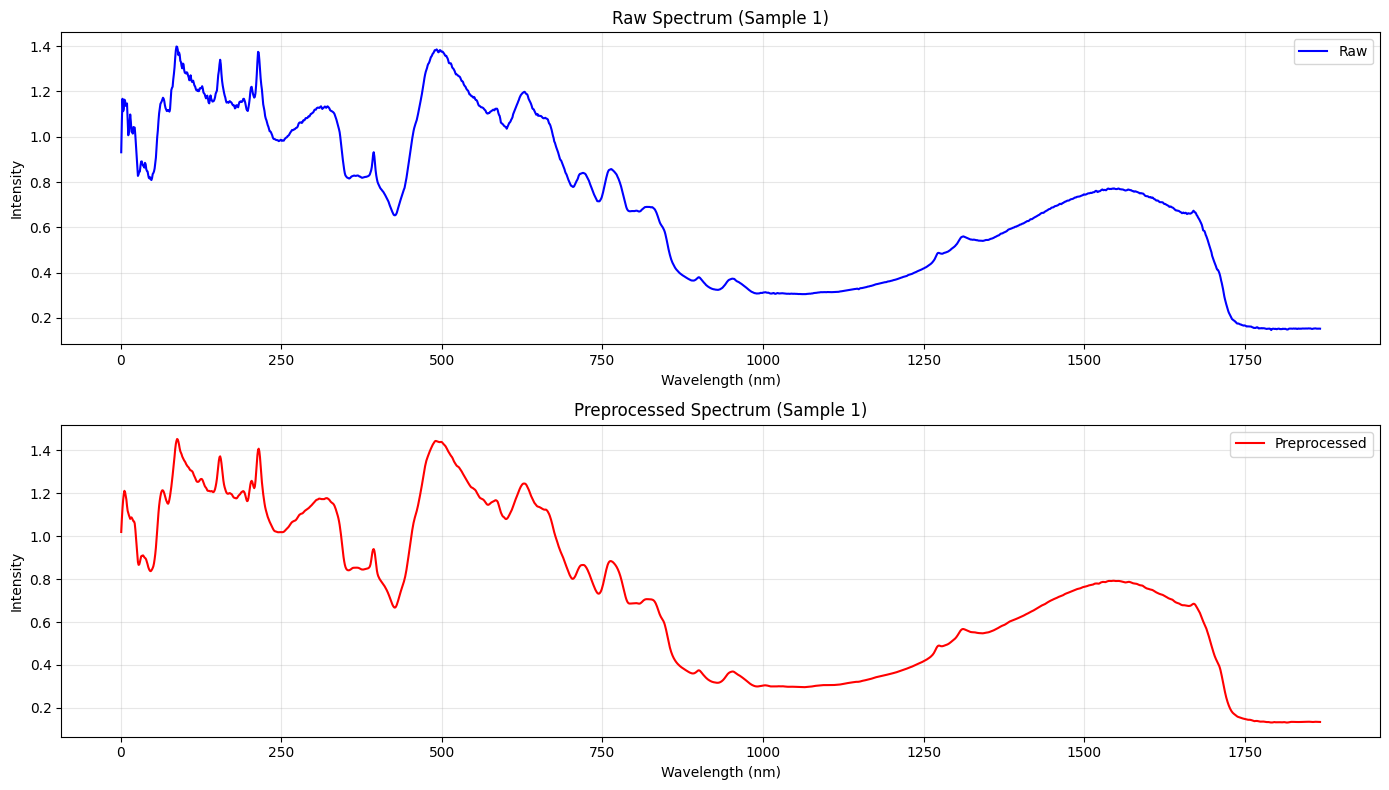


Saved: 02_preprocessing_comparison.png

Analysis complete! Check the generated files:
- 02_preprocessing_comparison.png


In [7]:
# 4. Preprocessing
X_raw = X.copy()
X_processed2 = preprocess_pipeline(X, baseline='msc', smooth=True, 
                                    derivative=1, window_length=11,
                                    polyorder=2)
visualize_preprocessing(X_raw, X_processed2, sample_idx=0, wavelengths=wavelengths)

print("\nAnalysis complete! Check the generated files:")
print("- 02_preprocessing_comparison.png")

In [8]:
# 5. Train-test split (BEFORE feature selection!)
X_train, X_test, y_train, y_test = train_test_split(
    X_processed, y, test_size=0.2, random_state=42
)
print(f"\nTrain set: {X_train.shape[0]} samples and {X_train.shape[1]} features")
print(f"Test set: {X_test.shape[0]} samples and {X_test.shape[1]} features")
print(f"\nTrain set: {y_train.shape[0]} samples and {y_train.shape[1]} labels")
print(f"Test set: {y_test.shape[0]} samples and {y_test.shape[1]} labels")


Train set: 200 samples and 1867 features
Test set: 51 samples and 1867 features

Train set: 200 samples and 5 labels
Test set: 51 samples and 5 labels


In [9]:
import numpy as np
import pandas as pd
from sklearn.feature_selection import VarianceThreshold
from sklearn.cross_decomposition import PLSRegression

# === 1️⃣ VARIANCE FILTER ===
# Remove wavelengths with very low variance across samples
var_thresh = 1e-5
var_selector = VarianceThreshold(threshold=var_thresh)
X_train_var = var_selector.fit_transform(X_train)
X_test_var = var_selector.transform(X_test)
mask_var = var_selector.get_support()
print(f"Variance filter → kept {X_train_var.shape[1]} features (removed {np.sum(~mask_var)})")

Variance filter → kept 1867 features (removed 0)


In [10]:
# === 2️⃣ CORRELATION FILTER ===
# Compute correlation of each wavelength with any enzyme
corr_threshold = 0.01
corrs = np.corrcoef(X_train[:, mask_var], y_train, rowvar=False)
corrs_xy = corrs[:X_train_var.shape[1], X_train_var.shape[1]:]  # X vs Y block
max_corr = np.nanmax(np.abs(corrs_xy), axis=1)       # strongest correlation per wavelength
mask_corr = max_corr > corr_threshold

X_train_corr = X_train_var[:, mask_corr]
X_test_corr = X_test_var[:, mask_corr]
print(f"Correlation filter → kept {X_train_corr.shape[1]} features (removed {np.sum(~mask_corr)})")

Correlation filter → kept 1867 features (removed 0)


In [11]:
print(X_train_corr.shape[0])
print(y_train.shape[0])


200
200


In [13]:
# hyperspec_fs_pls.py
from sklearn.cross_decomposition import PLSRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold, train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from tqdm import trange
import random
import time

# ---------------------------
# Utility metrics
# ---------------------------
def rmse(y, y_pred):
    return np.sqrt(mean_squared_error(y, y_pred))

def rpd(y, y_pred):
    sd = np.std(y, ddof=1)
    rm = rmse(y, y_pred)
    return sd / rm if rm != 0 else np.nan

def accuracy_within_pct(y, y_pred, pct=0.10):
    # fraction of predictions within ±pct of true value
    eps = pct * np.abs(y)
    # for true value zero, use absolute tolerance small value
    eps = np.where(eps == 0, pct * (np.max(np.abs(y)) + 1e-6), eps)
    return np.mean(np.abs(y - y_pred) <= eps)

# ---------------------------
# Prefiltering function: select top-k wavelengths by absolute Pearson correlation with y
# ---------------------------
def prefilter_topk(X_train, y_train, k=300):
    # Compute average absolute pearson r across folds or across samples for a single enzyme y_train (vector)
    # returns indices of top k features
    from scipy.stats import pearsonr
    n_features = X_train.shape[1]
    r_vals = np.zeros(n_features)
    for j in range(n_features):
        try:
            r_vals[j] = abs(pearsonr(X_train[:, j], y_train)[0])
        except Exception:
            r_vals[j] = 0.0
    idx = np.argsort(r_vals)[::-1][:k]
    return idx, r_vals

# ---------------------------
# PLS fitness evaluation inside CV
# ---------------------------
def evaluate_mask_pls(mask, X, y, n_splits=5, max_comp=8, scale_y=True, alpha_penalty=0.0, random_state=None):
    # mask: boolean array length = number of candidate features (subset)
    # X: shape (n_samples, n_candidate_features)
    # y: shape (n_samples,)
    # returns: fitness_value (lower better), mean_rmse, mean_r2
    if mask.sum() == 0:
        return 1e6, None, None, 0  # huge penalty for empty set

    selected = np.where(mask)[0]
    X_sel = X[:, selected]

    kf = KFold(n_splits=n_splits, shuffle=True, random_state=random_state)
    rmses = []
    r2s = []
    for train_idx, val_idx in kf.split(X_sel):
        Xt, Xv = X_sel[train_idx], X_sel[val_idx]
        yt, yv = y[train_idx], y[val_idx]

        # scale X
        sx = StandardScaler().fit(Xt)
        Xt_s = sx.transform(Xt)
        Xv_s = sx.transform(Xv)

        # scale y optionally
        if scale_y:
            sy = StandardScaler().fit(yt.reshape(-1,1))
            yt_s = sy.transform(yt.reshape(-1,1)).ravel()
            # we'll inverse transform predictions later when computing RMSE
        else:
            yt_s = yt

        # choose n_components via small loop
        best_rmse = np.inf
        best_pred = None
        for n_comp in range(1, min(max_comp, Xt_s.shape[1]) + 1):
            pls = PLSRegression(n_components=n_comp)
            pls.fit(Xt_s, yt_s.reshape(-1,1))
            yv_pred_s = pls.predict(Xv_s).ravel()
            if scale_y:
                yv_pred = sy.inverse_transform(yv_pred_s.reshape(-1,1)).ravel()
            else:
                yv_pred = yv_pred_s
            cur_rmse = rmse(yv, yv_pred)
            if cur_rmse < best_rmse:
                best_rmse = cur_rmse
                best_pred = (yv, yv_pred)

        rmses.append(best_rmse)
        r2s.append(r2_score(best_pred[0], best_pred[1]))

    mean_rmse = float(np.mean(rmses))
    mean_r2 = float(np.mean(r2s))
    # fitness includes penalty for number of features (normalized)
    penalty = alpha_penalty * (mask.sum() / X.shape[1])
    fitness = mean_rmse + penalty
    return fitness, mean_rmse, mean_r2, mask.sum()

# ---------------------------
# Simple Genetic Algorithm (binary mask)
# ---------------------------
def ga_binary_feature_selection(X, y, pop_size=30, n_gens=40, cx_prob=0.8, mut_prob=0.02, k_best_keep=2,
                                alpha_penalty=0.0, n_splits=5, max_comp=8, scale_y=True, verbose=True):
    n_features = X.shape[1]
    # init population: random masks with ~10% features selected (tweakable)
    pop = [np.random.rand(n_features) < 0.10 for _ in range(pop_size)]
    history = []
    best_overall = None

    for gen in range(n_gens):
        fitnesses = []
        details = []
        for i, ind in enumerate(pop):
            fit, mean_rmse, mean_r2, n_feats = evaluate_mask_pls(ind, X, y, n_splits=n_splits,
                                                                 max_comp=max_comp, scale_y=scale_y,
                                                                 alpha_penalty=alpha_penalty, random_state=gen+i)
            fitnesses.append(fit)
            details.append((fit, mean_rmse, mean_r2, n_feats))
        fitnesses = np.array(fitnesses)
        # record best
        best_idx = np.argmin(fitnesses)
        best_fit = fitnesses[best_idx]
        best_mask = pop[best_idx].copy()
        best_det = details[best_idx]

        if verbose:
            print(f"GA Gen {gen+1}/{n_gens} | best fitness {best_fit:.4f} | mean_rmse {best_det[1]:.4f} | n_feats {best_det[3]}")

        history.append((gen, best_fit, best_det))
        if best_overall is None or best_fit < best_overall[0]:
            best_overall = (best_fit, best_mask.copy(), best_det)

        # selection: tournament
        new_pop = []
        # keep top k_best_keep elites
        elite_idx = np.argsort(fitnesses)[:k_best_keep]
        for idx in elite_idx:
            new_pop.append(pop[idx].copy())

        while len(new_pop) < pop_size:
            # tournament selection
            i1, i2 = random.sample(range(pop_size), 2)
            parent1 = pop[i1] if fitnesses[i1] < fitnesses[i2] else pop[i2]
            i3, i4 = random.sample(range(pop_size), 2)
            parent2 = pop[i3] if fitnesses[i3] < fitnesses[i4] else pop[i4]
            # crossover
            if random.random() < cx_prob:
                pt = random.randint(1, n_features - 1)
                child = np.concatenate([parent1[:pt], parent2[pt:]])
            else:
                child = parent1.copy()
            # mutation (flip bits with low prob)
            for j in range(n_features):
                if random.random() < mut_prob:
                    child[j] = not child[j]
            new_pop.append(child.astype(bool))
        pop = new_pop[:pop_size]
    # return best mask and history
    return best_overall, history

# ---------------------------
# Simple Binary PSO (positions in [0,1] -> thresholding)
# ---------------------------
def binary_pso_feature_selection(X, y, pop_size=30, n_iter=40, w=0.5, c1=1.5, c2=1.5,
                                 threshold=0.5, alpha_penalty=0.0, n_splits=5, max_comp=8, scale_y=True, verbose=True):
    n_features = X.shape[1]
    # positions and velocities
    pos = np.random.rand(pop_size, n_features)
    vel = np.zeros_like(pos)
    pbest = pos.copy()
    pbest_mask = pos > threshold
    pbest_fit = np.array([evaluate_mask_pls(mask, X, y, n_splits=n_splits, max_comp=max_comp,
                                           scale_y=scale_y, alpha_penalty=alpha_penalty, random_state=i)[0]
                          for i, mask in enumerate(pbest_mask)])
    gbest_idx = np.argmin(pbest_fit)
    gbest = pbest[gbest_idx].copy()
    gbest_mask = pbest_mask[gbest_idx].copy()
    gbest_fit = pbest_fit[gbest_idx]

    history = []
    for it in range(n_iter):
        for i in range(pop_size):
            r1 = np.random.rand(n_features)
            r2 = np.random.rand(n_features)
            vel[i] = w*vel[i] + c1*r1*(pbest[i]-pos[i]) + c2*r2*(gbest-pos[i])
            pos[i] = pos[i] + vel[i]
            # clamp pos
            pos[i] = np.clip(pos[i], 0, 1)
            mask = pos[i] > threshold
            fitness, m_rmse, m_r2, n_feats = evaluate_mask_pls(mask, X, y, n_splits=n_splits, max_comp=max_comp,
                                                              scale_y=scale_y, alpha_penalty=alpha_penalty, random_state=it+i)
            if fitness < pbest_fit[i]:
                pbest_fit[i] = fitness
                pbest[i] = pos[i].copy()
        # update gbest
        gbest_idx = np.argmin(pbest_fit)
        if pbest_fit[gbest_idx] < gbest_fit:
            gbest_fit = pbest_fit[gbest_idx]
            gbest = pbest[gbest_idx].copy()
            gbest_mask = gbest > threshold

        if verbose:
            print(f"PSO Iter {it+1}/{n_iter} | best fitness {gbest_fit:.4f} | n_feats {np.sum(gbest_mask)}")
        history.append((it, gbest_fit, np.sum(gbest_mask)))
    return (gbest_fit, gbest_mask, None), history

# ---------------------------
# Wrapper to run optimizer for each enzyme
# ---------------------------
def run_for_enzyme(X_train, y_train, X_test, y_test, enzyme_idx, candidate_k=300,
                   method='GA', n_runs=1, verbose=True):
    # prefilter top k on X_train vs y_train (single enzyme)
    idx_candidates, corr_vals = prefilter_topk(X_train, y_train[:, enzyme_idx], k=candidate_k)
    Xtr_cand = X_train[:, idx_candidates]
    Xte_cand = X_test[:, idx_candidates]

    # optimizer params (tune as needed)
    if method == 'GA':
        best, history = ga_binary_feature_selection(Xtr_cand, y_train[:, enzyme_idx],
                                                    pop_size=30, n_gens=30, cx_prob=0.8, mut_prob=0.01,
                                                    k_best_keep=2, alpha_penalty=0.01,
                                                    n_splits=5, max_comp=8, scale_y=True, verbose=verbose)
        best_fit, best_mask, best_det = best
    elif method == 'PSO':
        best, history = binary_pso_feature_selection(Xtr_cand, y_train[:, enzyme_idx],
                                                     pop_size=30, n_iter=30, threshold=0.5, alpha_penalty=0.01,
                                                     n_splits=5, max_comp=8, scale_y=True, verbose=verbose)
        best_fit, best_mask, _ = best
    else:
        raise ValueError("method must be 'GA' or 'PSO' for this script")

    # Map mask back to original wavelengths
    selected_idx = np.array(idx_candidates)[best_mask]
    if verbose:
        print(f"Selected {selected_idx.size} wavelengths for enzyme {enzyme_idx}")

    # Train final PLS on full X_train with selected features
    if selected_idx.size == 0:
        raise RuntimeError("No features selected. Try lowering penalty or increasing pop/mutations.")
    # Fit scalers on X_train subset and y_train
    sx = StandardScaler().fit(X_train[:, selected_idx])
    sy = StandardScaler().fit(y_train[:, enzyme_idx].reshape(-1,1))
    Xtr_s = sx.transform(X_train[:, selected_idx])
    Xte_s = sx.transform(X_test[:, selected_idx])
    # choose n_components on full training set
    best_ncomp = 1
    best_rmse_inner = np.inf
    for nc in range(1, min(8, Xtr_s.shape[1]) + 1):
        pls = PLSRegression(n_components=nc)
        # simple CV for selection
        kf = KFold(n_splits=5, shuffle=True, random_state=0)
        preds = np.zeros_like(y_train[:, enzyme_idx])
        for tr, val in kf.split(Xtr_s):
            pls.fit(Xtr_s[tr], sy.transform(y_train[tr, enzyme_idx].reshape(-1,1)))
            p = pls.predict(Xtr_s[val]).ravel()
            preds[val] = sy.inverse_transform(p.reshape(-1,1)).ravel()
        cur_rmse = rmse(y_train[:, enzyme_idx], preds)
        if cur_rmse < best_rmse_inner:
            best_rmse_inner = cur_rmse
            best_ncomp = nc

    # final fit
    pls_final = PLSRegression(n_components=best_ncomp)
    pls_final.fit(Xtr_s, sy.transform(y_train[:, enzyme_idx].reshape(-1,1)))
    y_pred_test_s = pls_final.predict(Xte_s).ravel()
    y_pred_test = sy.inverse_transform(y_pred_test_s.reshape(-1,1)).ravel()

    # compute metrics on test
    test_rmse = rmse(y_test[:, enzyme_idx], y_pred_test)
    test_r2 = r2_score(y_test[:, enzyme_idx], y_pred_test)
    test_rpd = rpd(y_test[:, enzyme_idx], y_pred_test)
    test_acc10 = accuracy_within_pct(y_test[:, enzyme_idx], y_pred_test, pct=0.10)

    res = {
        "enzyme_idx": enzyme_idx,
        "method": method,
        "selected_wavelength_indices": selected_idx.tolist(),
        "selected_wavelength_names": [wavelengths[i] for i in selected_idx],
        "n_selected": selected_idx.size,
        "test_rmse": test_rmse,
        "test_r2": test_r2,
        "test_rpd": test_rpd,
        "test_acc10": test_acc10,
        "best_ncomp": best_ncomp,
        "history": history
    }
    return res



In [14]:
# ---------------------------
# Run for all enzymes
# ---------------------------
results = []
methods = ['GA', 'PSO']  # start with GA then PSO
for enzyme_idx in range(y_train.shape[1]):
    for method in methods:
        print("\n" + "="*60)
        print(f"Running enzyme {enzyme_idx} with method {method}")
        t0 = time.time()
        res = run_for_enzyme(X_train, y_train, X_test, y_test, enzyme_idx,
                             candidate_k=300, method=method, verbose=True)
        t1 = time.time()
        res['elapsed_seconds'] = t1 - t0
        results.append(res)
        print(f"Finished enzyme {enzyme_idx} method {method} in {res['elapsed_seconds']:.1f}s")
        print(f"Test RMSE: {res['test_rmse']:.4f} | R2: {res['test_r2']:.4f} | RPD: {res['test_rpd']:.4f} | acc±10%: {res['test_acc10']:.3f}")
        print("="*60 + "\n")

# Summary
print("\nFINAL SUMMARY")
df_summary = pd.DataFrame([{
    'enzyme': r['enzyme_idx'],
    'method': r['method'],
    'n_selected': r['n_selected'],
    'test_rmse': r['test_rmse'],
    'test_r2': r['test_r2'],
    'test_rpd': r['test_rpd'],
    'test_acc10': r['test_acc10'],
    'best_ncomp': r['best_ncomp'],
    'time_s': r['elapsed_seconds']
} for r in results])
print(df_summary)
# Optionally save selected wavelengths per enzyme/method
for r in results:
    fname = f"selected_wls_enzyme{r['enzyme_idx']}_{r['method']}.csv"
    pd.DataFrame({
        'index': r['selected_wavelength_indices'],
        'name': r['selected_wavelength_names']
    }).to_csv(fname, index=False)
    print("Saved selected wavelengths to", fname)



Running enzyme 0 with method GA
GA Gen 1/30 | best fitness 1606.6624 | mean_rmse 1606.6609 | n_feats 45
GA Gen 2/30 | best fitness 1630.7712 | mean_rmse 1630.7703 | n_feats 27
GA Gen 3/30 | best fitness 1627.7205 | mean_rmse 1627.7194 | n_feats 34
GA Gen 4/30 | best fitness 1607.5909 | mean_rmse 1607.5898 | n_feats 31
GA Gen 5/30 | best fitness 1615.9692 | mean_rmse 1615.9679 | n_feats 39
GA Gen 6/30 | best fitness 1609.1317 | mean_rmse 1609.1305 | n_feats 36
GA Gen 7/30 | best fitness 1606.9887 | mean_rmse 1606.9876 | n_feats 34
GA Gen 8/30 | best fitness 1604.8435 | mean_rmse 1604.8423 | n_feats 36
GA Gen 9/30 | best fitness 1599.4612 | mean_rmse 1599.4598 | n_feats 42
GA Gen 10/30 | best fitness 1581.6679 | mean_rmse 1581.6666 | n_feats 39
GA Gen 11/30 | best fitness 1605.5053 | mean_rmse 1605.5038 | n_feats 45
GA Gen 12/30 | best fitness 1596.7088 | mean_rmse 1596.7072 | n_feats 48
GA Gen 13/30 | best fitness 1597.1068 | mean_rmse 1597.1053 | n_feats 44
GA Gen 14/30 | best fitness

KeyboardInterrupt: 